# Solutions to the exercises of Chapter 7

Sample solutions for [Chapter 7, Spreading of a droplet](../../notebooks/part2_liquids_interfaces/07_spreading_droplet.ipynb).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## Exercise 1. A liquid ridge

Take a unit length of the ridge. Its cross-section is $h = h_c(1 - x^2/R^2)$ for
$-R < x < R$, with the area $\Omega = \tfrac43h_cR$. Hence

$$ h_c = \frac{3\Omega}{4R} , \qquad \theta = \frac{2h_c}{R} = \frac{3\Omega}{2R^2} . $$

*Free energy.* The wetted width is $2R$, so the cost of covering the solid is
$\tfrac12\gamma\theta_e^2\times 2R$. The excess length of the free surface is
$\int\tfrac12h'^2dx = 4h_c^2/3R = 3\Omega^2/4R^3$. Together

$$ A = \gamma\Big[\theta_e^2R + \frac{3\Omega^2}{4R^3}\Big] , \qquad -\frac{\partial A}{\partial R} = \gamma\Big[\frac{9\Omega^2}{4R^4} - \theta_e^2\Big] = 2\times\tfrac12\gamma\,(\theta^2 - \theta_e^2) . $$

The force is the unbalanced Young force on each of the two contact lines.

*Dissipation function.* For a family $h = R^{-1}f(x/R)$ the conservation of area,
$\partial h/\partial t + \partial(h\bar v)/\partial x = 0$, gives again $\bar v = x\dot R/R$. Then

$$ \Phi = \frac12\int_{-R+\epsilon}^{R-\epsilon}\frac{3\eta}{h}\,\bar v^2\,dx = \frac{3\eta\,\dot R^2R}{h_c}\int_0^{1-\delta}\frac{\xi^2}{1 - \xi^2}\,d\xi , \qquad \delta = \frac{\epsilon}{R} = \frac{b}{2h_c} . $$

The integral is $\tfrac12\ln(2/\delta) - 1$ for small $\delta$ (cell below), so that

$$ \Phi = \frac{3\eta\,\ell_2}{\theta}\,\dot R^2 = 2\times\tfrac12\,\xi_{\rm hyd}\,\dot R^2 , \qquad \ell_2 = \ln\frac{4h_c}{b} - 2 . $$

The friction of each contact line has the form of Eq. (7.7). Only the constant
inside the logarithm differs from the axisymmetric drop, because the flow far
from the edge is different.

*Kinetic equation.* $\partial\Phi/\partial\dot R = -\partial A/\partial R$ gives Eq. (7.8) with $\ell_2$:

$$ \dot R = \frac{\gamma}{6\eta\,\ell_2}\,\theta\,(\theta^2 - \theta_e^2) . $$

For complete wetting $\dot R = 9\gamma\Omega^3/16\eta\ell_2R^6$ and

$$ R^7 = R_0^7 + \frac{63\,\gamma\,\Omega^3}{16\,\eta\,\ell_2}\,t : $$

the ridge widens as $t^{1/7}$. The driving force and the friction depend on the
contact angle in the same way as for the drop; the exponent changes only because
the angle of a ridge falls as $R^{-2}$ and that of a drop as $R^{-3}$. The law
$t^{1/7}$ has been observed for stripes of silicone oil (McHale and co-workers,
1995).

*Check.* In the units of Section 7.5, $\Omega = \tfrac43$, $h_c = 1/R$ and
$\theta = 2/R^2$, and the kinetic equation is $dR/dt = \theta^3/2\ell_2$.

In [2]:
xi, delta = sp.symbols("xi delta", positive=True)
print("integral =", sp.series(sp.integrate(xi**2 / (1 - xi**2), (xi, 0, 1 - delta)), delta, 0, 1))

x, R, Rdot, Om, gam, eta, the_e, ell2 = sp.symbols("x R Rdot Omega gamma eta theta_e ell_2", positive=True)
h_ridge = 3 * Om / (4 * R) * (1 - x**2 / R**2)
print("area conservation:", sp.simplify(sp.diff(h_ridge, R) * Rdot + sp.diff(h_ridge * x * Rdot / R, x)))
A_ridge = gam * (the_e**2 * R + sp.integrate(sp.Rational(1, 2) * sp.diff(h_ridge, x) ** 2, (x, -R, R)))
theta_ridge = 3 * Om / (2 * R**2)
Phi_ridge = 3 * eta * ell2 / theta_ridge * Rdot**2
eq = on.kinetic_equations(A_ridge, Phi_ridge, [R], [Rdot])
print("Rdot - Eq. (7.8):", sp.simplify(eq[Rdot] - gam * theta_ridge * (theta_ridge**2 - the_e**2) / (6 * eta * ell2)))

# thin-film equation for a ridge on a precursor film
b = 3e-3
times = np.concatenate(([0.0], np.logspace(-2, 3, 101)))
edges = np.linspace(0.0, 4.2, 1681)
xc = 0.5 * (edges[1:] + edges[:-1])
xc, h = on.thin_film_fv(np.maximum(1 - xc**2, 0.0) + b, edges, times, geometry="planar")
fit = np.array([on.fit_cap(xc, hk, b=b) for hk in h])
R_num = fit[:, 1]

def rate(t, R):
    return [(2 / R[0] ** 2) ** 3 / (2 * (np.log(4 / (R[0] * b)) - 2))]
R_var = solve_ivp(rate, (times[41], times[-1]), [R_num[41]], t_eval=times[41:], rtol=1e-10, atol=1e-13).y[0]
print(f"largest difference in R for 1 < t < 1000: {100*np.max(np.abs(R_var/R_num[41:] - 1)):.2f} %")
print(f"fitted exponent for t > 30: thin film {on.loglog_slope(times, R_num, fit_range=(30, 1000))[0]:.4f},"
      f" kinetic equation {on.loglog_slope(times[41:], R_var, fit_range=(30, 1000))[0]:.4f},  1/7 = {1/7:.4f}")

integral = log(2)/2 - 1 - log(delta)/2 + O(delta)
area conservation: 0
Rdot - Eq. (7.8): 0


largest difference in R for 1 < t < 1000: 1.76 %
fitted exponent for t > 30: thin film 0.1485, kinetic equation 0.1477,  1/7 = 0.1429


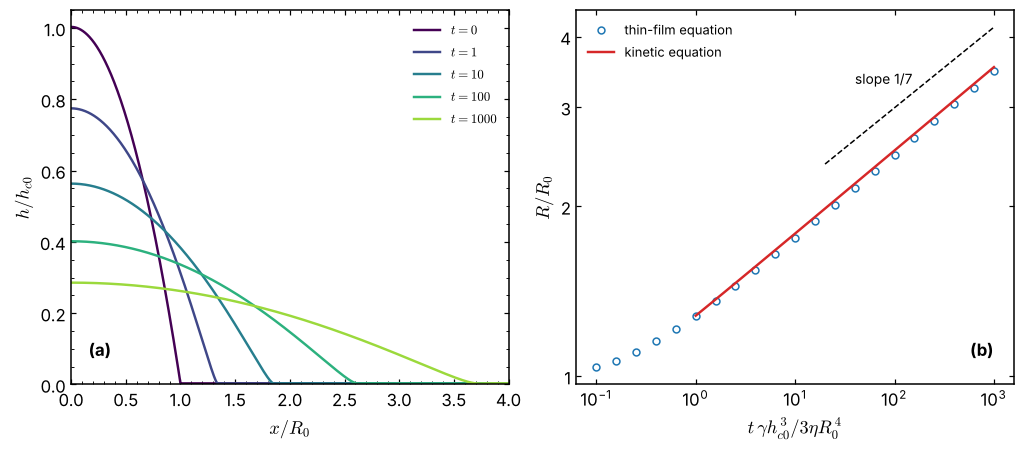

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 4.0))
shown = [0, 41, 61, 81, 101]
colors = plt.cm.viridis(np.linspace(0.0, 0.85, len(shown)))
for k, color in zip(shown, colors):
    ax1.plot(xc, h[k], color=color, label=f"$t = {times[k]:g}$")
ax1.set_xlabel("$x/R_0$"); ax1.set_ylabel("$h/h_{c0}$"); ax1.set_xlim(0, 4); ax1.set_ylim(0, 1.05)
ax1.legend(loc="upper right", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.04, y=0.12)

ax2.loglog(times[21::4], R_num[21::4], "o", color="C0", mfc="none", ms=4.5, label="thin-film equation")
ax2.loglog(times[41:], R_var, "-", color="C3", label="kinetic equation")
tt = np.array([20.0, 1000.0])
ax2.loglog(tt, 1.55 * tt ** (1 / 7), "k--", lw=1); ax2.text(40, 3.3, "slope 1/7", fontsize=9)
ax2.set_xlabel(r"$t\,\gamma h_{c0}^3/3\eta R_0^4$"); ax2.set_ylabel("$R/R_0$")
ax2.set_yticks([1, 2, 3, 4]); ax2.set_yticklabels(["1", "2", "3", "4"]); ax2.minorticks_off()
ax2.legend(loc="upper left", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.9, y=0.12)
plt.show()

**Figure S7.1.** **(a)** Half of the cross-section of a ridge spreading on a
precursor film of thickness $b = 0.003$ (thin-film equation, planar geometry).
**(b)** Half-width against time. The kinetic equation is started from the
numerical half-width at $t = 1$.

The half-width from the kinetic equation stays within 2 % of the thin-film
result. The fitted exponent is a little above $1/7 = 0.143$ for the same reason
as in Section 7.5: the logarithm $\ell_2$ falls slowly as the ridge flattens.

## Exercise 2. The approach to equilibrium

Write $R = R_e(1 + u)$ with $\lvert u\rvert \ll 1$. Since $\theta \propto R^{-3}$,
$\theta = \theta_e(1 - 3u)$ and $\theta^2 - \theta_e^2 = -6\theta_e^2u$ to first order. Equation
(7.8) becomes

$$ R_e\,\dot u = \frac{\gamma}{6\eta\,\ell}\,\theta_e\,(-6\theta_e^2u) \qquad\Longrightarrow\qquad \dot u = -\frac{u}{\tau} , \qquad \tau = \frac{\eta\,\ell\,R_e}{\gamma\,\theta_e^3} . $$

The relaxation time is the time $\eta R_e/\gamma$ that the capillary velocity needs
to cross the drop, multiplied by $\ell/\theta_e^3$. A small equilibrium angle makes
the relaxation slow twice over: the restoring force is proportional to
$\theta_e^2$ (a thin drop has little excess surface to gain or lose), and the
friction of the wedge is proportional to $1/\theta_e$.

The cell evaluates $\tau$ with $\ell = 10$ and integrates Eq. (7.8) for a drop that
starts 30 % too narrow and one that starts 30 % too wide.

silicone oil (1 Pa s)  tau = 17.6 s
water                  tau = 0.00514 s
too narrow : late decay rate 1.0000 / tau (theory 1);  half of the way after 0.15 tau
too wide   : late decay rate 0.9988 / tau (theory 1);  half of the way after 2.40 tau


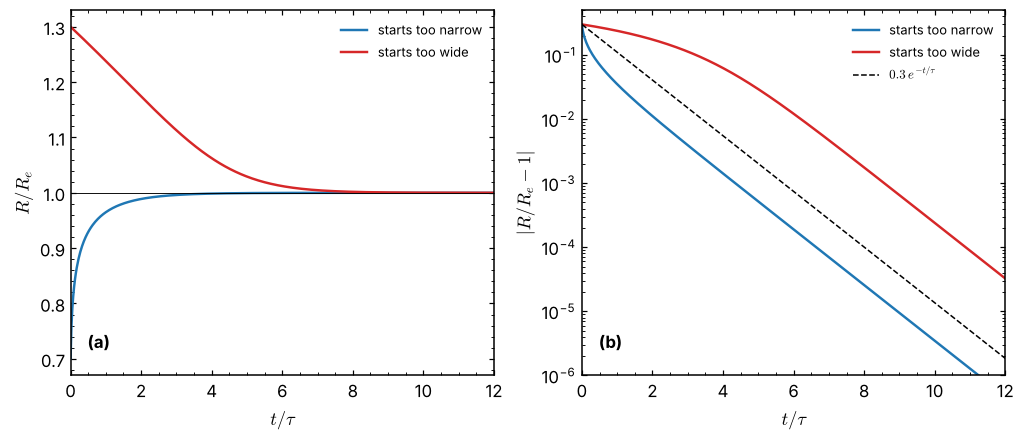

In [4]:
ell = 10.0
for name, eta_, gamma_ in (("silicone oil (1 Pa s)", 1.0, 0.021), ("water", 1.0e-3, 0.072)):
    print(f"{name:22s} tau = {eta_ * ell * 1e-3 / (gamma_ * 0.3**3):.3g} s")

# Eq. (7.8) in units of R_e and tau, with ell constant:  du/dT = -(theta/theta_e) [(theta/theta_e)^2 - 1] / 6
def relax(T, R):
    q = R[0] ** -3
    return [q * (q**2 - 1) / 6]

T = np.linspace(0, 12, 481)
narrow = solve_ivp(relax, (0, 12), [0.7], t_eval=T, rtol=1e-10, atol=1e-13).y[0]
wide = solve_ivp(relax, (0, 12), [1.3], t_eval=T, rtol=1e-10, atol=1e-13).y[0]
for name, curve in (("too narrow", narrow), ("too wide", wide)):
    late = (T > 9)
    rate_fit = -np.polyfit(T[late], np.log(np.abs(curve[late] - 1)), 1)[0]
    half = T[np.argmax(np.abs(curve - 1) < 0.15)]
    print(f"{name:11s}: late decay rate {rate_fit:.4f} / tau (theory 1);  half of the way after {half:.2f} tau")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
ax1.plot(T, narrow, color="C0", label="starts too narrow")
ax1.plot(T, wide, color="C3", label="starts too wide")
ax1.axhline(1, color="k", lw=0.6)
ax1.set_xlabel(r"$t/\tau$"); ax1.set_ylabel("$R/R_e$"); ax1.set_xlim(0, 12)
ax1.legend(loc="upper right", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.04, y=0.12)
ax2.semilogy(T, np.abs(narrow - 1), color="C0", label="starts too narrow")
ax2.semilogy(T, np.abs(wide - 1), color="C3", label="starts too wide")
ax2.semilogy(T, 0.3 * np.exp(-T), "k--", lw=1, label=r"$0.3\,e^{-t/\tau}$")
ax2.set_xlabel(r"$t/\tau$"); ax2.set_ylabel(r"$|R/R_e - 1|$"); ax2.set_xlim(0, 12); ax2.set_ylim(1e-6, 0.5)
ax2.legend(loc="upper right", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.04, y=0.12)
plt.show()

**Figure S7.2.** Relaxation of a partially wetting drop to its equilibrium
radius, from Eq. (7.8) with a constant $\ell$. **(a)** Radius against time.
**(b)** Distance from equilibrium on a logarithmic scale; the dashed line has
the slope $-1/\tau$.

For the viscous oil the relaxation takes tens of seconds and is easy to follow.
For water $\tau$ is a few milliseconds; on that time scale the inertia of the
water is not negligible, and the overdamped description of this chapter is at
the limit of its validity, as in Section 6.4.

Both drops approach equilibrium at the rate $1/\tau$ once they are close. Far
from equilibrium they differ: the narrow drop, whose contact angle is large, moves
quickly, because both the force and the mobility of the wedge are larger; the
wide drop, with its small angle, retracts slowly.

## Exercise 3. Heavy drops

**(a) The cap with gravity.** The gravitational energy of a film is
$\int\tfrac12\rho g h^2\,dS$ (the centre of mass of each column is at $h/2$). For
the cap (7.1),

$$ A_g = \tfrac12\rho g\,h_c^2\int_0^R\Big(1 - \frac{r^2}{R^2}\Big)^2 2\pi r\,dr = \frac{\pi}{6}\rho g\,h_c^2R^2 = \frac{2\rho g\,\Omega^2}{3\pi R^2} . $$

The two driving forces, for complete wetting, are

$$ -\frac{\partial}{\partial R}\,\frac{4\gamma\Omega^2}{\pi R^4} = \frac{16\gamma\Omega^2}{\pi R^5} , \qquad -\frac{\partial A_g}{\partial R} = \frac{4\rho g\,\Omega^2}{3\pi R^3} . $$

Their ratio is $\rho gR^2/12\gamma$: gravity is the stronger when

$$ R > 2\sqrt3\,\kappa^{-1} , \qquad \kappa^{-1} = \Big(\frac{\gamma}{\rho g}\Big)^{1/2} , $$

about 5 mm for the silicone oil of Section 7.4 and 9 mm for water. Drops narrower
than this spread by capillarity, as assumed in the chapter. With gravity alone
and the dissipation function (7.6),

$$ \frac{3\pi^2\eta\,\ell}{2\Omega}R^4\dot R = \frac{4\rho g\,\Omega^2}{3\pi R^3} \qquad\Longrightarrow\qquad R^8 = R_0^8 + \frac{64\,\rho g\,\Omega^3}{9\pi^3\eta\,\ell}\,t , $$

so that $R \propto t^{1/8}$.

**(b) The gravity current.** When gravity dominates, the pressure in the drop is
hydrostatic and a uniform pressure no longer means a uniform curvature. The
profile is $h = h_c(1 - r^2/R^2)^{1/3}$. Its volume is
$\Omega = \tfrac{3\pi}{4}h_cR^2$, so $h_c = 4\Omega/3\pi R^2$, and

$$ A_g = \pi\rho g\,h_c^2R^2\int_0^1(1 - \xi^2)^{2/3}\xi\,d\xi = \frac{3\pi}{10}\rho g\,h_c^2R^2 = \frac{8\rho g\,\Omega^2}{15\pi R^2} . $$

The family has the form $R^{-2}f(r/R)$, so $\bar v = r\dot R/R$ as before and

$$ \Phi = \frac{3\pi\eta\,\dot R^2R^2}{h_c}\int_0^1\frac{\xi^3}{(1 - \xi^2)^{1/3}}\,d\xi = \frac{27\pi\eta\,R^2\dot R^2}{20\,h_c} = \frac{81\pi^2\eta}{80\,\Omega}R^4\dot R^2 . $$

*No cut-off is needed* because the edge of this profile is blunt: near the edge
$h \propto (R - r)^{1/3}$, the film is much thicker than a wedge, and
$\int dr/(R - r)^{1/3}$ converges. The dissipation is spread over the whole drop.
(The real edge of a heavy drop is still a wedge on the scale of the capillary
length; its friction is negligible when the drop is much wider than that.)

Minimising, $\partial\Phi/\partial\dot R = -\partial A_g/\partial R$:

$$ \frac{81\pi^2\eta}{40\,\Omega}R^4\dot R = \frac{16\rho g\,\Omega^2}{15\pi R^3} \qquad\Longrightarrow\qquad R^8 = \frac{2^{10}}{3^5\pi^3}\,\frac{\rho g\,\Omega^3}{\eta}\,t . $$

In the usual form, $R = 0.894\,(\rho g\Omega^3/3\eta)^{1/8}\,t^{1/8}$ with
$0.894 = (2^{10}/3^4\pi^3)^{1/8}$: Huppert's result.

*Why exact.* The profile $(1 - r^2/R^2)^{1/3}$ with $R \propto t^{1/8}$ is an exact
solution of the thin-film equation with gravity,
$\partial h/\partial t = (\rho g/3\eta)\,r^{-1}\partial_r(r h^3\partial_r h)$; the cell below verifies this by
substitution. The trial family therefore contains the exact solution, and the
velocity field (7.5) is the exact one. The one remaining unknown, $\dot R$, is
fixed by the energy balance $\dot A = -2\Phi$, which the exact solution satisfies.
A variational calculation with a trial family returns the exact answer whenever
the family contains it. In the chapter the cap is not an exact solution near the
edge, and the coefficient of the logarithm suffers.

In [5]:
r, R, Rdot, Om, rho, g, eta, t, xi = sp.symbols("r R Rdot Omega rho g eta t xi", positive=True)

# (a) the cap
h_cap = 2 * Om / (sp.pi * R**2) * (1 - r**2 / R**2)
print("(a) A_g =", sp.simplify(sp.integrate(sp.Rational(1, 2) * rho * g * h_cap**2 * 2 * sp.pi * r, (r, 0, R))))

# (b) the gravity current, in the variable xi = r/R
hc = 4 * Om / (3 * sp.pi * R**2)
A_g = sp.pi * rho * g * hc**2 * R**2 * sp.integrate((1 - xi) ** sp.Rational(2, 3) / 2, (xi, 0, 1))      # xi -> xi^2
Phi = 3 * sp.pi * eta * Rdot**2 * R**2 / hc * sp.integrate(xi * (1 - xi) ** sp.Rational(-1, 3) / 2, (xi, 0, 1))
print("(b) A_g =", sp.simplify(A_g), "   Phi =", sp.simplify(Phi))
law = on.kinetic_equations(A_g, Phi, [R], [Rdot])[Rdot]
coefficient = sp.simplify(8 * R**7 * law * eta / (rho * g * Om**3))
print("    d(R^8)/dt in units of rho g Omega^3 / eta:", coefficient, "  (1024 = 2^10, 243 = 3^5)")
print("    Huppert's constant:", float((sp.Integer(2) ** 10 / (3**4 * sp.pi**3)) ** sp.Rational(1, 8)))

# the similarity solution with the variational coefficient satisfies the thin-film equation with gravity
c_var = sp.Rational(1024, 243) / sp.pi**3 * rho * g * Om**3 / eta
R_t = (c_var * t) ** sp.Rational(1, 8)
h_sim = 4 * Om / (3 * sp.pi * R_t**2) * (1 - r**2 / R_t**2) ** sp.Rational(1, 3)
residual = sp.diff(h_sim, t) - rho * g / (3 * eta) * sp.diff(r * h_sim**3 * sp.diff(h_sim, r), r) / r
values = {Om: 1.3, rho: 1.1, g: 0.7, eta: 0.9, t: 2.0}
R_now = float(R_t.subs(values))
print("    residual of the thin-film equation, relative to dh/dt, at r/R = 0.2, 0.5, 0.9:",
      [f"{abs(float((residual / sp.diff(h_sim, t)).subs(values).subs(r, f * R_now))):.1e}" for f in (0.2, 0.5, 0.9)])

(a) A_g = 2*Omega**2*g*rho/(3*pi*R**2)


(b) A_g = 8*Omega**2*g*rho/(15*pi*R**2)    Phi = 81*pi**2*R**4*Rdot**2*eta/(80*Omega)
    d(R^8)/dt in units of rho g Omega^3 / eta: 1024/(243*pi**3)   (1024 = 2^10, 243 = 3^5)
    Huppert's constant: 0.8939138475664
    residual of the thin-film equation, relative to dh/dt, at r/R = 0.2, 0.5, 0.9: ['2.4e-16', '2.4e-16', '5.6e-16']


The similarity solution with the coefficient $2^{10}/3^5\pi^3$ of the variational
calculation satisfies the equation to rounding error at every point.

## Exercise 4. Friction at the contact line

The two frictions act on the same velocity and add:

$$ \Phi = \tfrac12\Big(\frac{3\eta\,\ell}{\theta} + \xi_{\rm cl}\Big)\dot R^2\times 2\pi R . $$

With the force (7.3) for complete wetting,

$$ \Big(\frac{3\eta\,\ell}{\theta} + \xi_{\rm cl}\Big)\dot R = \tfrac12\gamma\,\theta^2 . $$

The two terms in the bracket are equal at the angle $\theta^* = 3\eta\ell/\xi_{\rm cl}$.

*Large angles, $\theta \gg \theta^*$ (early times).* The friction of the line
dominates: $\dot R = \gamma\theta^2/2\xi_{\rm cl} = 8\gamma\Omega^2/\pi^2\xi_{\rm cl}R^6$, and

$$ R^7 = R_0^7 + \frac{56\,\gamma\,\Omega^2}{\pi^2\xi_{\rm cl}}\,t . $$

*Small angles, $\theta \ll \theta^*$ (late times).* The friction of the wedge grows as
$1/\theta$ and always wins in the end: Tanner's law, Eq. (7.9).

The crossover is at the radius $R^* = (4\Omega/\pi\theta^*)^{1/3}$. Measuring $R$ in
units of $R^*$ and the time in units of $2\xi_{\rm cl}R^*/\gamma\theta^{*2}$, the kinetic
equation is

$$ \Big(1 + \frac{1}{q}\Big)\frac{dR}{dt} = q^2 , \qquad q = \frac{\theta}{\theta^*} = R^{-3} , $$

with $\ell$ taken as constant. The cell integrates it from a radius well inside
the first regime.

local exponent at R = 0.3 R*: 0.1417   (1/7 = 0.1429)
local exponent at R = R*:     0.1214
local exponent at R = 5 R*:   0.1003   (1/10)


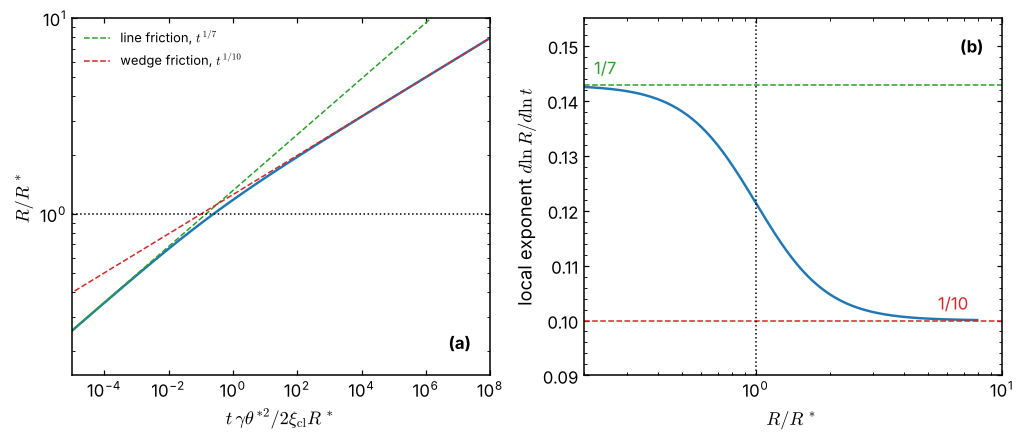

In [6]:
def rate(t, R):
    q = R[0] ** -3
    return [q**2 / (1 + 1 / q)]

t4 = np.logspace(-6, 8, 281)
R4 = solve_ivp(rate, (0, t4[-1]), [0.05], t_eval=t4, rtol=1e-10, atol=1e-14).y[0]
exponent = np.gradient(np.log(R4), np.log(t4))
print(f"local exponent at R = 0.3 R*: {np.interp(0.3, R4, exponent):.4f}   (1/7 = {1/7:.4f})")
print(f"local exponent at R = R*:     {np.interp(1.0, R4, exponent):.4f}")
print(f"local exponent at R = 5 R*:   {np.interp(5.0, R4, exponent):.4f}   (1/10)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
ax1.loglog(t4, R4, color="C0")
ax1.loglog(t4, (7 * t4) ** (1 / 7), "--", color="C2", lw=1, label=r"line friction, $t^{1/7}$")
ax1.loglog(t4, (10 * t4) ** 0.1, "--", color="C3", lw=1, label=r"wedge friction, $t^{1/10}$")
ax1.axhline(1, color="k", ls=":", lw=1)
ax1.set_xlabel(r"$t\,\gamma\theta^{*2}/2\xi_{\rm cl}R^*$"); ax1.set_ylabel("$R/R^*$")
ax1.set_xlim(1e-5, 1e8); ax1.set_ylim(0.15, 10)
ax1.legend(loc="upper left", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.9, y=0.12)
ax2.semilogx(R4, exponent, color="C0")
ax2.axhline(1 / 7, color="C2", ls="--", lw=1); ax2.axhline(0.1, color="C3", ls="--", lw=1)
ax2.text(0.22, 1 / 7 + 0.002, "1/7", color="C2"); ax2.text(5.5, 0.102, "1/10", color="C3")
ax2.axvline(1, color="k", ls=":", lw=1)
ax2.set_xlabel("$R/R^*$"); ax2.set_ylabel(r"local exponent $d\ln R/d\ln t$")
ax2.set_xlim(0.2, 10); ax2.set_ylim(0.09, 0.155)
on.panel_label(ax2, "(b)", x=0.9, y=0.95)
plt.show()

**Figure S7.3.** A drop with a friction at the contact line in addition to the
friction of the wedge. **(a)** Radius against time, with the two limiting laws.
**(b)** The local exponent. It moves from $1/7$ to $1/10$ over about a decade in
radius around $R^*$, which is many decades in time.

The crossover is slow. Since the radius grows as a small power of the time, a
decade in radius takes seven to ten decades in time, and an experiment that
covers three or four decades in time sees an apparent exponent somewhere between
$1/7$ and $1/10$. The exponent of a single experiment is therefore a poor guide
to the mechanism of dissipation; the dependence of the speed on the contact
angle, $\theta^2$ against $\theta^3$, is a better one. The same friction
$\xi_{\rm cl}$ appears in Chapter 9, where it decides the shape of the deposit left by
a drying drop.

It is a coincidence that the ridge of Exercise 1 and the drop with line friction
share the exponent $1/7$: in the first the geometry is different, in the second
the dissipation.